development notebook of updated algorithm

In [143]:
pip freeze > requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [136]:
import os
import numpy as np
import math
import pymc as pm
import pymc_bart as pmb
from pymc_bart.pgbart import PGBART
from numba import njit
import scipy as sp


# ==========================================
# 1. THE NUMBA ROULETTE WHEEL (SPARSITY)
# ==========================================
@njit(fastmath=True)
def sample_feature(alpha_vec):
    total_weight = np.sum(alpha_vec)
    r = np.random.uniform(0.0, total_weight)
    cumulative = 0.0
    for i in range(len(alpha_vec)):
        cumulative += alpha_vec[i]
        if r <= cumulative:
            return i
    return len(alpha_vec) - 1

@njit(fastmath=True)
def get_split_counts(F, num_features):
    counts = np.zeros(num_features, dtype=np.int32)
    m_trees = F.shape[0]
    max_nodes = F.shape[1]
    for m in range(m_trees):
        for i in range(max_nodes):
            feat = F[m, i]
            # THE FIX: Only count living features
            if feat >= 0: 
                counts[feat] += 1
    return counts

# ==========================================
# 2. THE MUTATIONS (Continuous & Localized)
# ==========================================
@njit(fastmath=True)
def get_active_leaves(F_tree, current_node_count):
    leaves = np.empty(current_node_count, dtype=np.int16)
    leaf_count = 0
    for i in range(current_node_count):
        if F_tree[i] == -1:
            leaves[leaf_count] = i
            leaf_count += 1
    return leaves[:leaf_count]

@njit(fastmath=True)
def get_prunable_nodes(F_tree, L_tree, R_tree, current_node_count):
    prunable = np.empty(current_node_count, dtype=np.int16)
    count = 0
    for i in range(current_node_count):
        if F_tree[i] >= 0:  # Ignore masked (-2) dead nodes
            left, right = L_tree[i], R_tree[i]
            if left != -1 and right != -1:
                if F_tree[left] == -1 and F_tree[right] == -1:
                    prunable[count] = i
                    count += 1
    return prunable[:count]

@njit(fastmath=True)
def get_internal_nodes(F_tree, current_node_count):
    internal = np.empty(current_node_count, dtype=np.int16)
    count = 0
    for i in range(current_node_count):
        if F_tree[i] >= 0:  # Ignore masked (-2) dead nodes
            internal[count] = i
            count += 1
    return internal[:count]

@njit(fastmath=True)
def is_split_valid(X, F_tree, T_tree, L_tree, R_tree, target_node, split_feat, split_val, min_node_size):
    n_rows = X.shape[0]
    left_count, right_count = 0, 0
    
    for i in range(n_rows):
        node = 0
        while F_tree[node] != -1 and node != target_node:
            if X[i, F_tree[node]] <= T_tree[node]: node = L_tree[node]
            else: node = R_tree[node]
                
        if node == target_node:
            if X[i, split_feat] <= split_val: left_count += 1
            else: right_count += 1
                
    return (left_count >= min_node_size) and (right_count >= min_node_size)


@njit(fastmath=True)
def get_local_bounds(F_tree, T_tree, L_tree, R_tree, target_node, feature, global_min, global_max):
    local_min = global_min
    local_max = global_max
    
    max_nodes = F_tree.shape[0]
    parents = np.full(max_nodes, -1, dtype=np.int16)
    is_left = np.zeros(max_nodes, dtype=np.bool_)
    
    for i in range(max_nodes):
        if F_tree[i] >= 0:
            l, r = L_tree[i], R_tree[i]
            if l != -1: 
                parents[l] = i
                is_left[l] = True
            if r != -1:
                parents[r] = i
                is_left[r] = False
                
    curr = target_node
    while curr != 0:
        p = parents[curr]
        if p == -1: break 
        
        if F_tree[p] == feature:
            if is_left[curr]:
                if T_tree[p] < local_max: local_max = T_tree[p]
            else:
                if T_tree[p] > local_min: local_min = T_tree[p]
        curr = p
        
    return local_min, local_max


@njit(fastmath=True)
def propose_grow(tree_idx, X, F, T, L, R, V, D, node_counts, alpha_vec, leaf_prior_std, min_node_size, global_mins, global_maxes):
    current_count = node_counts[tree_idx]
    leaves = get_active_leaves(F[tree_idx], current_count)
    if current_count >= F.shape[1] - 1: return False, -1, 0.0, -1, -1, current_count
        
    random_idx = np.random.randint(0, len(leaves))
    leaf_to_split = leaves[random_idx]
    
    split_feature = sample_feature(alpha_vec)
    global_min = global_mins[split_feature]
    global_max = global_maxes[split_feature]
    local_min, local_max = get_local_bounds(F[tree_idx], T[tree_idx], L[tree_idx], R[tree_idx], leaf_to_split, split_feature, global_min, global_max)
    
    if local_min == local_max: return False, -1, 0.0, -1, -1, current_count
    
    split_value = np.random.uniform(local_min, local_max)

    if not is_split_valid(X, F[tree_idx], T[tree_idx], L[tree_idx], R[tree_idx], 
                          leaf_to_split, split_feature, split_value, min_node_size):
        return False, -1, 0.0, -1, -1, current_count
    
    # GARBAGE COLLECTION: Scan for dead (-2) nodes to recycle
    left_child_idx, right_child_idx = -1, -1
    for i in range(current_count):
        if F[tree_idx, i] == -2:
            if left_child_idx == -1: left_child_idx = i
            elif right_child_idx == -1: 
                right_child_idx = i
                break
                
    new_count = current_count
    if left_child_idx == -1:
        left_child_idx = new_count
        new_count += 1
    if right_child_idx == -1:
        right_child_idx = new_count
        new_count += 1
        
    if new_count >= F.shape[1]: return False, -1, 0.0, -1, -1, current_count
    
    F[tree_idx, leaf_to_split] = split_feature
    T[tree_idx, leaf_to_split] = split_value
    L[tree_idx, leaf_to_split] = left_child_idx
    R[tree_idx, leaf_to_split] = right_child_idx
    F[tree_idx, left_child_idx] = -1
    F[tree_idx, right_child_idx] = -1
    
    parent_depth = D[tree_idx, leaf_to_split]
    D[tree_idx, left_child_idx] = parent_depth + 1
    D[tree_idx, right_child_idx] = parent_depth + 1

    V[tree_idx, left_child_idx] = np.random.normal(0.0, leaf_prior_std)
    V[tree_idx, right_child_idx] = np.random.normal(0.0, leaf_prior_std)
    
    node_counts[tree_idx] = new_count
    feat_range = max(local_max - local_min, 1e-5)
    return True, leaf_to_split, feat_range, left_child_idx, right_child_idx, current_count


@njit(fastmath=True)
def propose_prune(tree_idx, X, F, T, L, R, V, node_counts, leaf_prior_std, global_mins, global_maxes):
    current_count = node_counts[tree_idx]
    prunable_nodes = get_prunable_nodes(F[tree_idx], L[tree_idx], R[tree_idx], current_count)
    if len(prunable_nodes) == 0: return False, -1, -1, 0.0
        
    random_idx = np.random.randint(0, len(prunable_nodes))
    node_to_prune = prunable_nodes[random_idx]
    old_feature = F[tree_idx, node_to_prune]
    
    global_min = global_mins[old_feature]
    global_max = global_maxes[old_feature]
    local_min, local_max = get_local_bounds(F[tree_idx], T[tree_idx], L[tree_idx], R[tree_idx], node_to_prune, old_feature, global_min, global_max)
    feat_range = max(local_max - local_min, 1e-5)
    
    F[tree_idx, node_to_prune] = -1
    F[tree_idx, L[tree_idx, node_to_prune]] = -2 # Mask dead children
    F[tree_idx, R[tree_idx, node_to_prune]] = -2 # Mask dead children
    
    V[tree_idx, node_to_prune] = np.random.normal(0.0, leaf_prior_std)
    return True, node_to_prune, old_feature, feat_range


@njit(fastmath=True)
def propose_change(tree_idx, X, F, T, L, R, node_counts, alpha_vec, min_node_size, global_mins, global_maxes):
    current_count = node_counts[tree_idx]
    internal_nodes = get_internal_nodes(F[tree_idx], current_count)
    if len(internal_nodes) == 0: return False, -1, -1, 0.0, 0.0, 0.0
        
    random_idx = np.random.randint(0, len(internal_nodes))
    node_to_change = internal_nodes[random_idx]
    
    old_feature = F[tree_idx, node_to_change]
    old_threshold = T[tree_idx, node_to_change]
    
    global_min = global_mins[old_feature]
    global_max = global_maxes[old_feature]
    old_min, old_max = get_local_bounds(F[tree_idx], T[tree_idx], L[tree_idx], R[tree_idx], node_to_change, old_feature, global_min, global_max)
    old_feat_range = max(old_max - old_min, 1e-5)
    
    new_feature = sample_feature(alpha_vec)
    global_min = global_mins[new_feature]
    global_max = global_maxes[new_feature]
    new_min, new_max = get_local_bounds(F[tree_idx], T[tree_idx], L[tree_idx], R[tree_idx], node_to_change, new_feature, global_min, global_max)    
    
    if new_min == new_max: return False, -1, -1, 0.0, 0.0, 0.0
    
    new_threshold = np.random.uniform(new_min, new_max)
    new_feat_range = max(new_max - new_min, 1e-5)
    
    if not is_split_valid(X, F[tree_idx], T[tree_idx], L[tree_idx], R[tree_idx], 
                          node_to_change, new_feature, new_threshold, min_node_size):
        return False, -1, -1, 0.0, 0.0, 0.0 
    
    F[tree_idx, node_to_change] = new_feature
    T[tree_idx, node_to_change] = new_threshold
    
    return True, node_to_change, old_feature, old_threshold, old_feat_range, new_feat_range


# ==========================================
# 3. LIKELIHOOD AND PRIORS
# ==========================================
@njit(fastmath=True)
def get_tree_prediction(X, F_tree, T_tree, L_tree, R_tree, V_tree, out_preds):
    out_preds[:] = 0.0 
    n_rows = X.shape[0]
    for i in range(n_rows):
        node = 0
        while F_tree[node] != -1:
            if X[i, F_tree[node]] <= T_tree[node]:
                node = L_tree[node]
            else:
                node = R_tree[node]
        out_preds[i] = V_tree[node]

@njit(fastmath=True)
def calc_marginal_loglik(X, Z, partial_pred, F_tree, T_tree, L_tree, R_tree, leaf_prior_std, sum_res, count, current_nodes):
    sum_res[:current_nodes] = 0.0 
    count[:current_nodes] = 0     
    n_rows = X.shape[0]
    
    for i in range(n_rows):
        node = 0
        while F_tree[node] != -1:
            if X[i, F_tree[node]] <= T_tree[node]: node = L_tree[node]
            else: node = R_tree[node]
        
        sum_res[node] += (Z[i] - partial_pred[i])
        count[node] += 1
        
    tau2 = leaf_prior_std ** 2
    log_lik = 0.0
    
    for node in range(current_nodes):
        if F_tree[node] == -1 and count[node] > 0:
            n = count[node]
            term1 = -0.5 * math.log(1.0 + n * tau2)
            term2 = (tau2 * (sum_res[node] ** 2)) / (2.0 * (1.0 + n * tau2))
            log_lik += (term1 + term2)
            
    return log_lik

@njit(fastmath=True)
def update_leaves_gibbs(X, Z, partial_pred, F_tree, T_tree, L_tree, R_tree, V_tree, leaf_prior_std, sum_res, count, current_nodes):
    sum_res[:current_nodes] = 0.0 
    count[:current_nodes] = 0     
    n_rows = X.shape[0]
    
    for i in range(n_rows):
        node = 0
        while F_tree[node] != -1:
            if X[i, F_tree[node]] <= T_tree[node]: node = L_tree[node]
            else: node = R_tree[node]
            
        sum_res[node] += (Z[i] - partial_pred[i])
        count[node] += 1
        
    tau2 = leaf_prior_std ** 2
    
    for node in range(current_nodes):
        if F_tree[node] == -1 and count[node] > 0:
            n = count[node]
            post_var = tau2 / (1.0 + n * tau2)
            post_mean = post_var * sum_res[node]
            V_tree[node] = post_mean + np.random.normal(0.0, math.sqrt(post_var))


@njit(fastmath=True)
def calc_grow_prior_ratio(node_depth, leaf_priors):
    if node_depth + 1 >= len(leaf_priors): return -1e9  
    p_leaf_d = leaf_priors[node_depth]
    p_leaf_d_plus_1 = leaf_priors[node_depth + 1]
    p_split = 1.0 - p_leaf_d
    if p_leaf_d <= 0.0 or p_split <= 0.0: return -1e9
    prior_ratio = (p_split * (p_leaf_d_plus_1 ** 2)) / p_leaf_d
    return math.log(prior_ratio)

@njit(fastmath=True)
def draw_latent_z_numba(Y, eta):
    n = Y.shape[0]
    Z = np.empty(n, dtype=np.float32)
    for i in range(n):
        mu = eta[i]
        if Y[i] == 1:
            if mu < -3.0: mu = -3.0
            while True:
                z = np.random.normal(mu, 1.0)
                if z > 0:
                    Z[i] = z
                    break
        else:
            if mu > 3.0: mu = 3.0
            while True:
                z = np.random.normal(mu, 1.0)
                if z <= 0:
                    Z[i] = z
                    break
    return Z


# ==========================================
# 4. MASTER SWEEP
# ==========================================
@njit(fastmath=True, cache=True)
def mcmc_fractional_sweep(X, Z, F, T, L, R, V, D, node_counts, 
                          sum_trees, alpha_vec, 
                          leaf_priors, leaf_prior_std,
                          step_size,
                          accept_stats,
                          update_fraction=0.1,
                          min_node_size = 5,
                          global_mins = None,
                          global_maxes = None
                          ):
    m_trees = F.shape[0]
    num_features = X.shape[1]

    n_to_update = max(1, int(m_trees * update_fraction))
    indices = np.arange(m_trees)
    np.random.shuffle(indices)
    trees_to_update = indices[:n_to_update]

    n_rows = X.shape[0]        
    max_nodes = F.shape[1]     
    
    pred_buffer = np.zeros(n_rows, dtype=np.float32)
    sum_res_buffer = np.zeros(max_nodes, dtype=np.float32)
    count_buffer = np.zeros(max_nodes, dtype=np.int32)
    
    for m in trees_to_update:
        accept_stats[0] += 1
        
        get_tree_prediction(X, F[m], T[m], L[m], R[m], V[m], pred_buffer)
        old_tree_pred = pred_buffer.copy() 
        
        partial_pred = sum_trees - old_tree_pred
        old_ll = calc_marginal_loglik(X, Z, partial_pred, F[m], T[m], L[m], R[m], leaf_prior_std, sum_res_buffer, count_buffer, node_counts[m])
        
        step_type = np.random.random()
        mutation_type = -1  
        success = False
        penalty = 0.0
        
        is_stump = (F[m, 0] == -1)
        if is_stump:
            p_grow, p_prune, p_change = 1.0, 0.0, 0.0
        else:
            p_grow, p_prune, p_change = 0.33, 0.33, 0.34
        
        if step_type < p_grow:
            num_leaves_old = len(get_active_leaves(F[m], node_counts[m]))
            
            success, mutated_node, feat_range, left_idx, right_idx, old_count = propose_grow(m, X, F, T, L, R, V, D, node_counts, alpha_vec, leaf_prior_std, min_node_size, global_mins, global_maxes)
            if success: 
                num_prunable_new = len(get_prunable_nodes(F[m], L[m], R[m], node_counts[m]))
                prior_ratio = calc_grow_prior_ratio(D[m, mutated_node], leaf_priors)
                prob_ratio = math.log(0.33) - math.log(p_grow)
                # transition_ratio = math.log(num_leaves_old) - math.log(num_prunable_new) + math.log(num_features) + math.log(feat_range)
                transition_ratio = math.log(num_leaves_old) - math.log(num_prunable_new) 
                penalty = prior_ratio + transition_ratio + prob_ratio
            mutation_type = 0
            
        elif step_type < (p_grow + p_prune):
            num_prunable_old = len(get_prunable_nodes(F[m], L[m], R[m], node_counts[m]))
            
            success, mutated_node, old_feat, feat_range = propose_prune(m, X, F, T, L, R, V, node_counts, leaf_prior_std, global_mins, global_maxes)
            if success: 
                num_leaves_new = len(get_active_leaves(F[m], node_counts[m]))
                prior_ratio = -calc_grow_prior_ratio(D[m, mutated_node], leaf_priors)
                p_grow_new = 1.0 if (mutated_node == 0) else 0.33
                prob_ratio = math.log(p_grow_new) - math.log(p_prune)
                # transition_ratio = math.log(num_prunable_old) - math.log(num_leaves_new) - math.log(num_features) - math.log(feat_range)
                # transition_ratio = math.log(num_prunable_old) - math.log(num_leaves_new) 
                transition_ratio=0.0
                penalty = prior_ratio + transition_ratio + prob_ratio
            mutation_type = 1
            
        else:
            success, mutated_node, old_feat, old_thresh, old_feat_range, new_feat_range = propose_change(m, X, F, T, L, R, node_counts, alpha_vec, min_node_size, global_mins, global_maxes)
            if success:
                transition_ratio = math.log(new_feat_range) - math.log(old_feat_range)
                # transition_ratio = math.log(old_feat_range) - math.log(new_feat_range)
                penalty = transition_ratio
            mutation_type = 2
            
        if success:
            new_ll = calc_marginal_loglik(X, Z, partial_pred, F[m], T[m], L[m], R[m], leaf_prior_std, sum_res_buffer, count_buffer, node_counts[m])
            log_alpha = (new_ll - old_ll) + penalty
            accept = math.log(np.random.random()) < log_alpha
            
            if accept:
                accept_stats[1] += 1 
            else:
                if mutation_type == 0:
                    F[m, mutated_node] = -1
                    F[m, left_idx] = -2 
                    F[m, right_idx] = -2 
                    node_counts[m] = old_count
                elif mutation_type == 1:
                    F[m, mutated_node] = old_feat
                    F[m, L[m, mutated_node]] = -1
                    F[m, R[m, mutated_node]] = -1
                else:
                    F[m, mutated_node] = old_feat
                    T[m, mutated_node] = old_thresh

        # THIS MUST ALWAYS RUN
        update_leaves_gibbs(X, Z, partial_pred, F[m], T[m], L[m], R[m], V[m], leaf_prior_std, sum_res_buffer, count_buffer, node_counts[m])
        get_tree_prediction(X, F[m], T[m], L[m], R[m], V[m], pred_buffer)
        sum_trees[:] = partial_pred + pred_buffer

# ==========================================
# 5. PYTHON API HANDOFF
# ==========================================
class FastTreeState:
    def __init__(self, m_trees, init_mean, max_nodes=255):
        self.m_trees = m_trees
        self.max_nodes = max_nodes
        self.F = np.full((m_trees, max_nodes), -1, dtype=np.int16)
        self.L = np.full((m_trees, max_nodes), -1, dtype=np.int16)
        self.R = np.full((m_trees, max_nodes), -1, dtype=np.int16)
        self.D = np.ones((m_trees, max_nodes), dtype=np.int8)
        # self.D = np.zeros((m_trees, max_nodes), dtype=np.int8) 
        self.T = np.zeros((m_trees, max_nodes), dtype=np.float32)
        self.V = np.zeros((m_trees, max_nodes), dtype=np.float32)
        self.node_counts = np.ones(m_trees, dtype=np.int16)
        self.V[:, 0] = init_mean / m_trees


class FastSurvMHBART(PGBART):
    def __init__(self, vars, target_x=None, 
                 target_y=None, use_sparsity=True, 
                 update_fraction=1.0, 
                 k=2.0,
                 step_size=0.1,
                 min_node_size=5,
                 offset=None,
                 return_estimates=False, *args, **kwargs):
        super().__init__(vars, *args, **kwargs)
        
        self.accept_count = 0
        self.total_count = 0
        self.use_sparsity = use_sparsity
        self.update_fraction = update_fraction
        self.min_node_size = min_node_size
        
        if target_x is None or target_y is None or return_estimates == True:
            actual_X = self.X
            actual_Y = self.Y
            self.return_estimates = True
            print("returning estimates")
        else:
            self.return_estimates = False
            actual_X = target_x
            actual_Y = target_y
        
        if offset is None:
            base_prob = np.clip(actual_Y.mean(), 1e-5, 1.0 - 1e-5)
            self.offset = sp.stats.norm.ppf(base_prob)
        else:
            self.offset = offset
        
        self.c_tree_state = FastTreeState(m_trees=self.m, init_mean=0.0, max_nodes=255)
        self.flat_sum_trees = np.zeros(actual_X.shape[0], dtype=np.float32)
        self.k = k
        self.leaf_prior_std = float(3.0 / (self.k * np.sqrt(self.m)))
        self.step_size = step_size

        self.numba_X = np.copy(np.ascontiguousarray(actual_X))
        self.numba_Y = np.copy(np.ascontiguousarray(actual_Y)).ravel()
                
        self.global_mins = np.min(self.numba_X, axis=0).astype(np.float32)
        self.global_maxes = np.max(self.numba_X, axis=0).astype(np.float32)

        self.alpha_vec = np.ones(actual_X.shape[1], dtype=np.float32)
        self.numba_leaf_priors = np.array(self.prior_prob_leaf_node, dtype=np.float32)
        self.stats_dtypes = [{
            "variable_inclusion": np.ndarray,
            "tune": bool,
            "F_trees": np.ndarray,
            "T_trees": np.ndarray,
            "L_trees": np.ndarray,
            "R_trees": np.ndarray,
            "V_trees": np.ndarray,
            "node_counts": np.ndarray
        }]
        self.accept_stats = np.zeros(2, dtype=np.int64)

    def astep(self, q0):
        current_eta = self.flat_sum_trees + self.offset
        Z = draw_latent_z_numba(self.numba_Y, current_eta)
        
        Z_residual = Z - self.offset
        Z_numba = np.ascontiguousarray(Z_residual, dtype=np.float32)

        mcmc_fractional_sweep(
            self.numba_X, Z_numba, 
            self.c_tree_state.F, self.c_tree_state.T, 
            self.c_tree_state.L, self.c_tree_state.R, 
            self.c_tree_state.V, self.c_tree_state.D, 
            self.c_tree_state.node_counts,
            self.flat_sum_trees, 
            self.alpha_vec, 
            self.numba_leaf_priors,
            self.leaf_prior_std,
            self.step_size,
            self.accept_stats,
            self.update_fraction,
            self.min_node_size,
            self.global_mins,
            self.global_maxes
        )
        
        var_counts = get_split_counts(self.c_tree_state.F, self.num_variates)
        
        ## direlect
        # ==========================================
        # THE FIX: True DART Dirichlet Gibbs Update
        # ==========================================
        if self.use_sparsity:
            # Step 1: Set the base concentration 
            # (Use 1.0 for soft sparsity, or 1.0 / self.num_variates for aggressive sparsity)
            base_prior = 1.0 / self.num_variates 
            
            # Step 2: Combine base prior with observed structural counts
            concentration_params = base_prior + var_counts.astype(np.float64)
            
            # Step 3: Draw probabilistic weights from the Dirichlet simplex
            # This guarantees exploration while naturally zeroing out useless variables
            new_weights = np.random.dirichlet(concentration_params)
            
            self.alpha_vec = new_weights.astype(np.float32)


        stats = {
            "variable_inclusion": var_counts, 
            "tune": self.tune,
            "F_trees": self.c_tree_state.F.copy(),
            "T_trees": self.c_tree_state.T.copy(),
            "L_trees": self.c_tree_state.L.copy(),
            "R_trees": self.c_tree_state.R.copy(),
            "V_trees": self.c_tree_state.V.copy(),
            "node_counts": self.c_tree_state.node_counts.copy()
        }

        if self.return_estimates:
            self.sum_trees[0, 0, :] = self.flat_sum_trees
            return self.sum_trees, [stats]
        else:
            return np.zeros(1), [stats]

@njit(fastmath=True, parallel=False)
def _fast_predict_trace(X, F, T, L, R, V):
    n_samples = F.shape[0]
    m_trees = F.shape[1]
    n_obs = X.shape[0]
    preds = np.zeros((n_samples, n_obs), dtype=np.float32)
    for s in range(n_samples):
        for m in range(m_trees):
            f_tree = F[s, m]
            t_tree = T[s, m]
            l_tree = L[s, m]
            r_tree = R[s, m]
            v_tree = V[s, m]
            for i in range(n_obs):
                node = 0
                while f_tree[node] != -1:
                    feat = f_tree[node]
                    if X[i, feat] <= t_tree[node]:
                        node = l_tree[node]
                    else:
                        node = r_tree[node]
                preds[s, i] += v_tree[node]
    return preds

def predict_out_of_sample(trace, X_new, offset, m_trees=50, max_nodes=255, thin=1):
    print("Starting predict layout...")
    stats = trace.sample_stats
    n_samples_raw = stats["F_trees"].values.size // (m_trees * max_nodes)
    
    F = np.ascontiguousarray(stats["F_trees"].values).reshape(n_samples_raw, m_trees, max_nodes)[::thin].astype(np.int16, copy=False)
    T = np.ascontiguousarray(stats["T_trees"].values).reshape(n_samples_raw, m_trees, max_nodes)[::thin].astype(np.float32, copy=False)
    L = np.ascontiguousarray(stats["L_trees"].values).reshape(n_samples_raw, m_trees, max_nodes)[::thin].astype(np.int16, copy=False)
    R = np.ascontiguousarray(stats["R_trees"].values).reshape(n_samples_raw, m_trees, max_nodes)[::thin].astype(np.int16, copy=False)
    V = np.ascontiguousarray(stats["V_trees"].values).reshape(n_samples_raw, m_trees, max_nodes)[::thin].astype(np.float32, copy=False)
    
    n_samples_thinned = F.shape[0]
    X_numba = np.ascontiguousarray(X_new, dtype=np.float64)
    n_obs = X_new.shape[0]
    
    print(f"Processing: Dropping {n_obs} rows down {n_samples_thinned} thinned historical forests (Thin factor: {thin})...")
    raw_tree_sums = _fast_predict_trace(X_numba, F, T, L, R, V)
    latent_scores = raw_tree_sums + offset
    
    probabilities = sp.stats.norm.cdf(latent_scores)
    return probabilities


def simple_feature_importance(trace):
    raw_counts = trace.sample_stats["variable_inclusion"].values
    # 2. Sum the counts across all chains (axis=0) and all draws (axis=1)
    # This gives you a single 1D array of total splits per feature across the whole posterior
    total_counts = np.nansum(raw_counts, axis=(0, 1))

    # 3. Normalize to get relative feature importance (probabilities)
    feature_importance = total_counts / total_counts.sum()

    # 4. (Optional) Print the results neatly sorted by importance
    sorted_indices = np.argsort(feature_importance)[::-1]

    print("--- Posterior Feature Importance ---")
    for idx in sorted_indices:
        importance = feature_importance[idx]
        if importance > 0.001:  # Only show features that were actually used
            print(f"Feature {idx:2d}: {importance:.4f}  ({importance * 100:>5.2f}%)")

In [137]:
print("Generating Probit Friedman Data...")
N = 4000
P = 100 # 5 active features, 45 pure noise features

# Friedman requires inputs strictly in the [0, 1] interval
X_dummy = np.random.uniform(0, 1, size=(N, P))

# The classic Friedman equation
latent_raw = (
    10 * np.sin(np.pi * X_dummy[:, 0] * X_dummy[:, 1]) +  # Complex interaction
    20 * (X_dummy[:, 2] - 0.5)**2 +                       # Quadratic / U-shape
    10 * X_dummy[:, 3] +                                  # Linear strong
    5 * X_dummy[:, 4]                                     # Linear weak
)

# Standardize the latent score to prevent the Probit link from flatlining
latent_scaled = (latent_raw - np.mean(latent_raw)) / np.std(latent_raw)

# Multiply by a scalar (e.g., 1.5) to stretch it nicely across the tails
p = sp.stats.norm.cdf(latent_scaled * 1.5)
Y_dummy = np.random.binomial(1, p, size=N)

Generating Probit Friedman Data...


In [138]:
print("Generating TRUE Kang-Schafer Propensity Data...")
N = 2000

# 1. Z are the TRUE unobserved standard normal covariates
Z = np.random.normal(0, 1, size=(N, 4))

# 2. X are the OBSERVED covariates (complex non-linear transformations of Z)
# This is what BART will actually train on.
X_dummy = np.zeros((N, 4))
X_dummy[:, 0] = np.exp(Z[:, 0] / 2)
X_dummy[:, 1] = Z[:, 1] / (1 + np.exp(Z[:, 0])) + 10
X_dummy[:, 2] = (Z[:, 0] * Z[:, 2] / 25 + 0.6)**3
X_dummy[:, 3] = (Z[:, 1] + Z[:, 3] + 20)**2

# 3. The true propensity score is a LINEAR combination of the hidden Z
latent_raw = -Z[:, 0] + 0.5 * Z[:, 1] - 0.25 * Z[:, 2] - 0.1 * Z[:, 3]

# 4. Scale and apply Probit
latent_scaled = (latent_raw - np.mean(latent_raw)) / np.std(latent_raw)
p = sp.stats.norm.cdf(latent_scaled * 1.5)
Y_dummy = np.random.binomial(1, p, size=N)

Generating TRUE Kang-Schafer Propensity Data...


In [139]:
import matplotlib.pyplot as plt

# ==========================================
# 4. THE TEST RUN
# ==========================================
if __name__ == "__main__":
    import pytensor.tensor as pt
    print("Building model graph...")
    with pm.Model() as test_model:
        # ENGINE_MODE = "native" 
        # ENGINE_MODE = "fast_vanilla" 
        # ENGINE_MODE = "fast_sparse" 
        ENGINE_MODE = "fast_sparse_no_save" 

        trees = pmb.BART("trees", X=np.zeros((1,X_dummy.shape[1])), Y=np.zeros(1), m=50)
        # trees = pmb.BART("trees", X=X_dummy, Y=Y_dummy, m=100)
        
        # THE FIX: Translate latent tree scores to probabilities (Probit Link)
        prob = 0.5 * (1.0 + pt.erf(trees / pt.sqrt(2.0)))
        # prob = sp.stats.norm.pdf(trees)
        
        # THE FIX: Use Bernoulli for binary classification, NOT Normal
        obs = pm.Bernoulli("obs", p=prob, observed=Y_dummy)

        if ENGINE_MODE == "native":
            print("\n[CONFIG] Using Baseline PyMC Particle Gibbs BART...")
            custom_step = None
            
        elif ENGINE_MODE == "fast_vanilla":
            print("\n[CONFIG] Using Custom C-Engine (Uniform Feature)...")
            custom_step = FastSurvMHBART(
                vars=[trees], 
                use_sparsity=False, 
                update_fraction=.05,
                k=1.5,
                step_size = .1,
                )
            
        elif ENGINE_MODE == "fast_sparse":
            print("\n[CONFIG] Using Custom C-Engine (Dirichlet Sparsity)...")
            custom_step = FastSurvMHBART(
                vars=[trees], 
                use_sparsity=True, 
                update_fraction=.05,
                k=1.5,
                step_size=.1
                )
            
        elif ENGINE_MODE == "fast_sparse_no_save":
            print("\n[CONFIG] Using Custom C-Engine (Dirichlet Sparsity)...")
            custom_step = FastSurvMHBART(
                vars=[trees], 
                use_sparsity=False, 
                target_x = X_dummy,
                target_y = Y_dummy,
                update_fraction=1,
                k=2,
                step_size = .3,
                return_estimate = False
                )

        trace = pm.sample(
                draws=1000, 
                tune=1000, 
                chains=4, 
                cores=4,
                step=custom_step,  # If None, PyMC handles it
                compute_convergence_checks=False,
                progressbar=True,
                discard_tuned_samples=True
            )

Building model graph...

[CONFIG] Using Custom C-Engine (Dirichlet Sparsity)...


Multiprocess sampling (4 chains in 4 jobs)
FastSurvMHBART: [trees]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 12 seconds.


In [140]:
np.unique(trace.sample_stats["node_counts"].values, return_counts=True)


(array([ 7.,  9., 11., 13., nan], dtype=float32),
 array([  65807,  105913,   23894,    4386, 9800000]))

Starting predict layout...
Processing: Dropping 2000 rows down 4000 thinned historical forests (Thin factor: 1)...


(-0.01, 1.01)

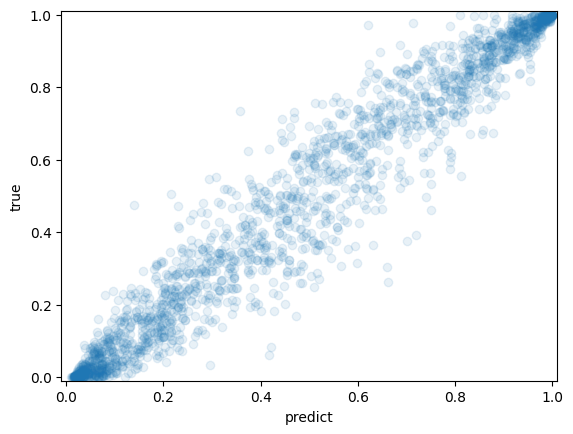

In [141]:
preds = predict_out_of_sample(trace, X_dummy, custom_step.offset, m_trees=50, thin=1)
preds = preds.mean(0)
plt.scatter(preds,p, alpha=.1)
# # 47
plt.xlabel("predict")
plt.ylabel("true")
plt.ylim(-.01,1.01)
plt.xlim(-0.01,1.01)

In [129]:

def simple_feature_importance(trace):
    raw_counts = trace.sample_stats["variable_inclusion"].values
    # 2. Sum the counts across all chains (axis=0) and all draws (axis=1)
    # This gives you a single 1D array of total splits per feature across the whole posterior
    total_counts = np.nansum(raw_counts, axis=(0, 1))

    # 3. Normalize to get relative feature importance (probabilities)
    feature_importance = total_counts / total_counts.sum()

    # 4. (Optional) Print the results neatly sorted by importance
    sorted_indices = np.argsort(feature_importance)[::-1]

    print("--- Posterior Feature Importance ---")
    for idx in sorted_indices:
        importance = feature_importance[idx]
        if importance > 0.001:  # Only show features that were actually used
            print(f"Feature {idx:2d}: {importance:.4f}  ({importance * 100:>5.2f}%)")
        

In [135]:
simple_feature_importance(trace)

--- Posterior Feature Importance ---
Feature  3: 0.0998  ( 9.98%)
Feature  1: 0.0990  ( 9.90%)
Feature  0: 0.0949  ( 9.49%)
Feature  2: 0.0799  ( 7.99%)
Feature  4: 0.0620  ( 6.20%)
Feature 35: 0.0191  ( 1.91%)
Feature 85: 0.0137  ( 1.37%)
Feature 53: 0.0117  ( 1.17%)
Feature 66: 0.0113  ( 1.13%)
Feature 22: 0.0108  ( 1.08%)
Feature 90: 0.0107  ( 1.07%)
Feature 79: 0.0107  ( 1.07%)
Feature 80: 0.0099  ( 0.99%)
Feature 96: 0.0092  ( 0.92%)
Feature 15: 0.0087  ( 0.87%)
Feature 77: 0.0086  ( 0.86%)
Feature 48: 0.0086  ( 0.86%)
Feature 28: 0.0085  ( 0.85%)
Feature 24: 0.0082  ( 0.82%)
Feature 47: 0.0081  ( 0.81%)
Feature 45: 0.0078  ( 0.78%)
Feature  9: 0.0078  ( 0.78%)
Feature 25: 0.0078  ( 0.78%)
Feature 99: 0.0078  ( 0.78%)
Feature 89: 0.0077  ( 0.77%)
Feature 82: 0.0074  ( 0.74%)
Feature 67: 0.0073  ( 0.73%)
Feature 54: 0.0070  ( 0.70%)
Feature 62: 0.0069  ( 0.69%)
Feature 61: 0.0067  ( 0.67%)
Feature 52: 0.0066  ( 0.66%)
Feature 29: 0.0066  ( 0.66%)
Feature 38: 0.0064  ( 0.64%)
Featur

In [111]:
print(np.sqrt(((p-preds)**2).mean()))
print(np.mean(p-preds))

0.06597752322902943
0.0021636156667714256


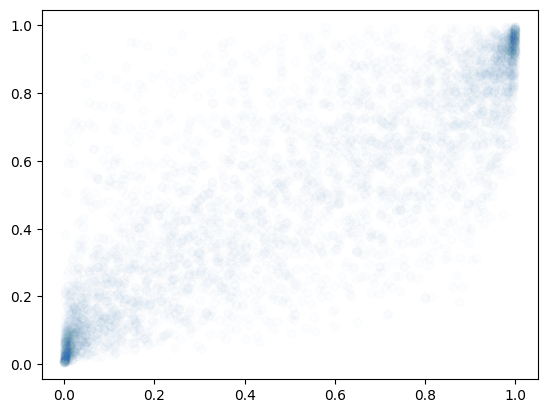

In [112]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression().fit(X_dummy, Y_dummy)
lg_pred = model.predict_proba(X_dummy)[:,1]
plt.scatter(p, lg_pred, alpha=.01)

In [113]:
print(np.sqrt(((p-lg_pred)**2).mean()))
print(np.mean(p-lg_pred))


0.19453429509903875
0.0026079695741192364
